In [90]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn import metrics
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [91]:
mnist=fetch_openml('mnist_784')
mnist.data.shape, mnist.target.shape
x_data=mnist.data
y_data=mnist.target.astype(int)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
X_train, X_test, y_train, y_test=train_test_split(x_data, y_data, test_size=0.20, random_state=42)

scaler = StandardScaler(with_mean=True, with_std=True)
X_train = scaler.fit_transform(X_train.values)
X_test  = scaler.transform(X_test.values)
X_train = torch.tensor(X_train, dtype=torch.float32, device=device)
X_test  = torch.tensor(X_test,  dtype=torch.float32, device=device)
y_train = torch.tensor(y_train.values, dtype=torch.long, device=device)
y_test  = torch.tensor(y_test.values,  dtype=torch.long, device=device)

# X_train, X_test=torch.Tensor(X_train.values), torch.Tensor(X_test.values)
# y_train, y_test=torch.LongTensor(y_train.values), torch.Tensor(y_test.values)
# X_train=X_train.to(device)
# X_test=X_test.to(device)
# y_train=y_train.to(device)
# y_test=y_test.to(device)

In [92]:
# class LogisticRegression(torch.nn.Module):
#   def __init__(self, input_dim, output_dim):
#     super(LogisticRegression, self).__init__()
#     self.linear=torch.nn.Linear(input_dim, output_dim)
#   def forward(self, x):
#     outputs=torch.sigmoid(self.linear(x))
#     return outputs

# m=nn.Linear(20,30)
# input=torch.randn(128,20)
# output=m(input)
# epochs=10000
# input_dim=784
# output_dim=10
# lr=0.01
# model=LogisticRegression(input_dim, output_dim)
# model=model.to(device)
# criterion=nn.CrossEntropyLoss()
# optimizer=torch.optim.SGD(model.parameters(), lr=lr)

class LogisticRegression(torch.nn.Module):
  def __init__(self, input_dim, output_dim):
    super().__init__()
    self.linear = torch.nn.Linear(input_dim, output_dim)
  def forward(self, x):
    return self.linear(x)

epochs = 10000
input_dim = 784
output_dim = 10
lr=0.01
model = LogisticRegression(input_dim, output_dim)
model=model.to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),lr=lr)

epochs = 10000

In [93]:
loss_save_arr_train = []
loss_save_arr_test  = []
for i in range(epochs):
    model.train()
    optimizer.zero_grad()
    output = model(X_train)
    loss = criterion(output, y_train.long())
    loss.backward()
    optimizer.step()
    if (i+1) % 10 == 0:
        model.eval()
        with torch.no_grad():
            test_output = model(X_test)
            test_loss = criterion(test_output, y_test.long())
        loss_save_arr_train.append(loss.item())
        loss_save_arr_test.append(test_loss.item())
    if (i+1) % 1000 == 0:
        print('epoch', i+1)
        _, pred = torch.max(output.data, axis=1)
        train_acc = float((pred == y_train).sum()) / y_train.size(0)
        print("train_accuracy {:0.3f}".format(train_acc))
        model.eval()
        with torch.no_grad():
            output = model(X_test)
            _, pred = torch.max(output.data, axis=1)
            test_acc = float((pred == y_test).sum()) / y_test.size(0)
            print("Test_accuracy {:0.3f}".format(test_acc))

epoch 1000
train_accuracy 0.903
Test_accuracy 0.900
epoch 2000
train_accuracy 0.913
Test_accuracy 0.910
epoch 3000
train_accuracy 0.918
Test_accuracy 0.913
epoch 4000
train_accuracy 0.921
Test_accuracy 0.915
epoch 5000
train_accuracy 0.923
Test_accuracy 0.916
epoch 6000
train_accuracy 0.924
Test_accuracy 0.918
epoch 7000
train_accuracy 0.925
Test_accuracy 0.918
epoch 8000
train_accuracy 0.926
Test_accuracy 0.919
epoch 9000
train_accuracy 0.927
Test_accuracy 0.919
epoch 10000
train_accuracy 0.928
Test_accuracy 0.919


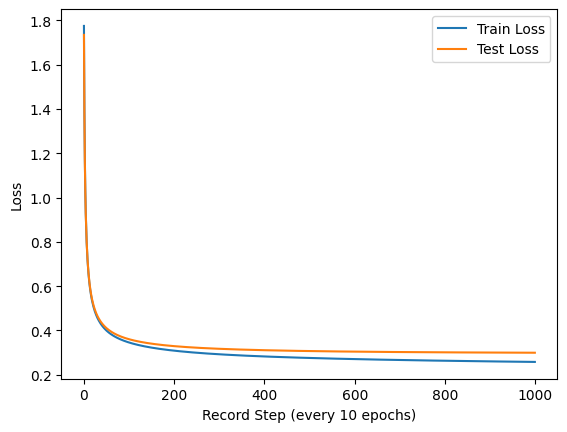

In [94]:
plt.plot(loss_save_arr_train, label='Train Loss')
plt.plot(loss_save_arr_test, label='Test Loss')
plt.xlabel('Record Step (every 10 epochs)')
plt.ylabel('Loss')
plt.legend()
plt.show()